<a href="https://colab.research.google.com/github/Raj-18-45/Machine-Learning/blob/main/Supervised%20Learning/Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Titanic Survival Prediction Using Random Forest**

Objective

To build a Random Forest classification model to predict whether a passenger survived the Titanic disaster based on passenger information.

About the Dataset

The Titanic dataset (titanic.csv) contains 891 records and 15 columns, including passenger information such as passenger class, sex, age, number of siblings or spouses aboard, number of parents or children aboard, fare, and port of embarkation.

The survived column is the target variable:

* 0: Did not survive
* 1: Survived

In [1]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
# Load and Explore Dataset
df=pd.read_csv('/content/titanic.csv')
print(df.shape)
print(df.info())
print(df.head)
print(df.describe())

(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB
None
<bound method NDFrame.head of      survived  pclass     sex   age  sibsp  parch     fare embar

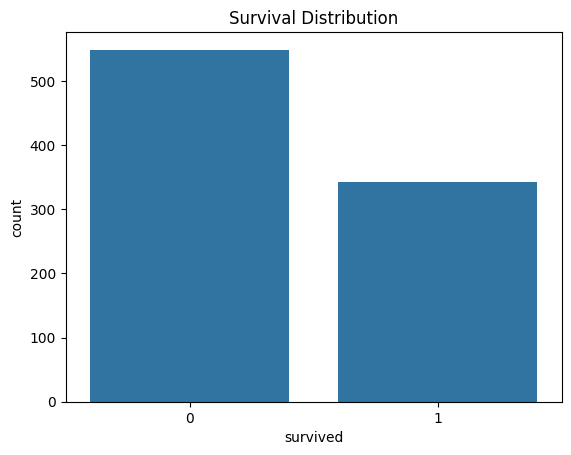

In [5]:
#Data Visualization
sns.countplot(data=df,x='survived')
plt.title("Survival Distribution")
plt.show()

In [6]:
#Handle Missing Values and Preprocess Data
df = df[['survived', 'pclass', 'sex', 'age',

         'sibsp', 'parch', 'fare', 'embarked']].copy()
# handling missing values
df['age'] = df['age'].fillna(df['age'].median())

df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
#    categorical text into numerical values.
le = LabelEncoder()

df['sex'] = le.fit_transform(df['sex'])

df['embarked'] = le.fit_transform(df['embarked'])

In [7]:
#Separate Input and Output Variables
X=df.drop('survived',axis=1)
y=df['survived']

In [8]:
#Split the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
#Train the Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [14]:
# Make Predictions
y_pred = model.predict(X_test)
print("Predicted Values:", y_pred)

Predicted Values: [0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1
 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 1 1 1 1
 0 0 1 1 1 1 0 1 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 1
 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 1 0 0 0 1 0 0 1 1 0 1 0 0 0 0 1 1 0 0 1 0 1
 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 1 0 0 0 1 1]


In [15]:
#Evaluate the Model
print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n", cm)

Accuracy: 0.8212290502793296
Confusion Matrix:
 [[92 13]
 [19 55]]


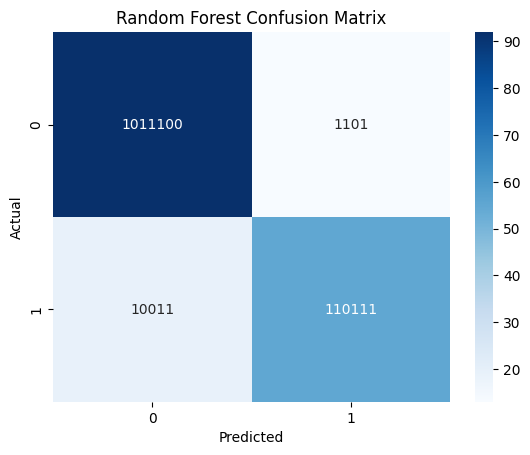

In [17]:
# Visualize the Evaluation Results
sns.heatmap(cm,annot=True, fmt='b',cmap='Blues')
plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [18]:
#Predict Survival for a New Passenger
new_passenger = pd.DataFrame({
    'pclass': [1],
    'sex': [0],       # Female
    'age': [25],
    'sibsp': [0],
    'parch': [0],
    'fare': [80],
    'embarked': [0]   # Encoded port value
})

prediction = model.predict(new_passenger)[0]

print("Prediction:", "Survived" if prediction == 1 else "Did not survive")

Prediction: Survived
